In [1]:
import sys
!{sys.executable} -m pip install matplotlib

In [2]:
from pathlib import Path
import kagglehub

raw_data = Path("data/raw")
raw_data.mkdir(parents=True, exist_ok=True)

datasets = {
    "strategy": "yajatpawar/formula-1-strategy-dataset",
    "formula1": "melissamonfared/formula-1",
    "podiums": "maulikgajera/formula-one-race-podiums-19502026",
}

for name, dataset_id in datasets.items():
    print(f"Downloading {name}...")
    kagglehub.dataset_download(
        dataset_id,
        output_dir=str(raw_data / name)
    )

print("Finished downloading.")

ConnectionError: HTTPSConnectionPool(host='api.kaggle.com', port=443): Max retries exceeded with url: /v1/datasets.DatasetApiService/GetDataset (Caused by NewConnectionError("HTTPSConnection(host='api.kaggle.com', port=443): Failed to establish a new connection: [WinError 10013] An attempt was made to access a socket in a way forbidden by its access permissions"))

In [ ]:
for csv_file in raw_data.rglob("*.csv"):
    print(csv_file)
    

data\raw\formula1\circuits.csv
data\raw\formula1\constructors.csv
data\raw\formula1\constructor_results.csv
data\raw\formula1\constructor_standings.csv
data\raw\formula1\drivers.csv
data\raw\formula1\driver_standings.csv
data\raw\formula1\lap_times.csv
data\raw\formula1\pit_stops.csv
data\raw\formula1\qualifying.csv
data\raw\formula1\races.csv
data\raw\formula1\results.csv
data\raw\formula1\seasons.csv
data\raw\formula1\sprint_results.csv
data\raw\formula1\status.csv
data\raw\podiums\f1_podiums_1950_2026.csv
data\raw\strategy\f1_strategy_final_dataset.csv


In [3]:
import pandas as pd

tables = {}

for csv_file in raw_data.rglob("*.csv"):
    table_name = csv_file.stem
    df = pd.read_csv(csv_file)
    tables[table_name] = df

    print(f"\n--- {csv_file.name} ---")
    print("Rows and columns:", df.shape)
    print("Column names:", df.columns.tolist())
    display(df.head(3))
    


--- circuits.csv ---
Rows and columns: (77, 9)
Column names: ['circuitId', 'circuitRef', 'name', 'location', 'country', 'lat', 'lng', 'alt', 'url']


,circuitId,circuitRef,name,location,country,lat,lng,alt,url
0,1,albert_park,Albert Park Grand Prix Circuit,Melbourne,Australia,-37.84970,144.9680,10,http://en.wikipedia.org/wiki/Melbourne_Grand_P...
1,2,sepang,Sepang International Circuit,Kuala Lumpur,Malaysia,2.76083,101.7380,18,http://en.wikipedia.org/wiki/Sepang_Internatio...
2,3,bahrain,Bahrain International Circuit,Sakhir,Bahrain,26.03250,50.5106,7,http://en.wikipedia.org/wiki/Bahrain_Internati...



--- constructors.csv ---
Rows and columns: (212, 5)
Column names: ['constructorId', 'constructorRef', 'name', 'nationality', 'url']


,constructorId,constructorRef,name,nationality,url
0,1,mclaren,McLaren,British,http://en.wikipedia.org/wiki/McLaren
1,2,bmw_sauber,BMW Sauber,German,http://en.wikipedia.org/wiki/BMW_Sauber
2,3,williams,Williams,British,http://en.wikipedia.org/wiki/Williams_Grand_Pr...



--- constructor_results.csv ---
Rows and columns: (12495, 5)
Column names: ['constructorResultsId', 'raceId', 'constructorId', 'points', 'status']


,constructorResultsId,raceId,constructorId,points,status
0,1,18,1,14.0,\N
1,2,18,2,8.0,\N
2,3,18,3,9.0,\N


... (22 outputs left out)


--- f1_podiums_1950_2026.csv ---
Rows and columns: (1158, 9)
Column names: ['Season', 'Grand Prix', 'Round', 'Race Date', 'Circuit', 'Country', 'Winner', 'Second Place Driver', 'Third Place Driver']


,Season,Grand Prix,Round,Race Date,Circuit,Country,Winner,Second Place Driver,Third Place Driver
0,1950,British Grand Prix,1,1950-05-13,Silverstone Circuit,United Kingdom,Giuseppe Farina,Luigi Fagioli,Reg Parnell
1,1950,Monaco Grand Prix,2,1950-05-21,Circuit de Monaco,Monaco,Juan Manuel Fangio,Alberto Ascari,Louis Chiron
2,1950,Indianapolis 500,3,1950-05-30,Indianapolis Motor Speedway,United States,Johnnie Parsons,Bill Holland,Mauri Rose



--- f1_strategy_final_dataset.csv ---
Rows and columns: (80767, 28)
Column names: ['Year', 'EventName', 'RoundNumber', 'Driver', 'DriverNumber', 'Team', 'LapNumber', 'Stint', 'IsPersonalBest', 'Compound', 'CompoundCode', 'TyreLife', 'FreshTyre', 'LapTimeSec', 'Sector1TimeSec', 'Sector2TimeSec', 'Sector3TimeSec', 'IsPitLap', 'LapsUntilNextPit', 'IsSC', 'IsVSC', 'IsDRS', 'Position', 'GridPosition', 'AirTemp', 'TrackTemp', 'Rainfall', 'WindSpeed']


,Year,EventName,RoundNumber,Driver,DriverNumber,Team,LapNumber,Stint,IsPersonalBest,Compound,...,LapsUntilNextPit,IsSC,IsVSC,IsDRS,Position,GridPosition,AirTemp,TrackTemp,Rainfall,WindSpeed
0,2021,Bahrain Grand Prix,1,ALO,14,Alpine,1.0,1.0,False,SOFT,...,10,0,0,0,8.0,9.0,20.5,28.1,False,1.3
1,2021,Bahrain Grand Prix,1,ALO,14,Alpine,2.0,1.0,True,SOFT,...,9,1,0,0,8.0,9.0,20.5,28.1,False,1.1
2,2021,Bahrain Grand Prix,1,ALO,14,Alpine,4.0,1.0,True,SOFT,...,7,0,0,0,7.0,9.0,20.5,28.0,False,1.0


In [37]:
import pandas as pd
from pathlib import Path

f1_dir = raw_data / "formula1"

races = pd.read_csv(f1_dir / "races.csv", na_values=r"\N")
results = pd.read_csv(f1_dir / "results.csv", na_values=r"\N")
drivers = pd.read_csv(f1_dir / "drivers.csv", na_values=r"\N")

podiums = pd.read_csv(
    next(raw_data.rglob("f1_podiums_1950_2026.csv"))
)

strategy = pd.read_csv(
    next(raw_data.rglob("f1_strategy_final_dataset.csv"))
)

print(races.shape, results.shape, drivers.shape, podiums.shape, strategy.shape)

(1125, 18) (26499, 18) (859, 9) (1158, 9) (80767, 28)


In [38]:
results_full["driver_code"] = results_full["code"].astype(str).str.strip().str.upper()
strategy_summary["driver_code"] = strategy_summary["Driver"].astype(str).str.strip().str.upper()

KeyError: 'Driver'

In [ ]:
results_full["driver_code"] = results_full["code"].astype("string").str.strip().str.upper()
strategy_summary["driver_code"] = strategy_summary["Driver"].astype("string").str.strip().str.upper()

In [ ]:
validate="one_to_one"


In [ ]:
validate="many_to_one"

In [ ]:
combined = results_full.merge(
    strategy_summary,
    left_on=["year", "round", "driver_code"],
    right_on=["Year", "RoundNumber", "driver_code"],
    how="left",
    validate="many_to_one"
)

In [ ]:
# Race information
race_info = races[["raceId", "year", "round", "name", "date", "circuitId"]]

# Add race and driver details to official result rows
results_full = (
    results
    .merge(race_info, on="raceId", how="left")
    .merge(
        drivers[["driverId", "code", "forename", "surname"]],
        on="driverId",
        how="left"
    )
)

# Clean join values BEFORE grouping
results_full["year"] = pd.to_numeric(results_full["year"], errors="coerce").astype("Int64")
results_full["round"] = pd.to_numeric(results_full["round"], errors="coerce").astype("Int64")
results_full["driver_code"] = (
    results_full["code"].astype("string").str.strip().str.upper()
)

strategy["year"] = pd.to_numeric(strategy["Year"], errors="coerce").astype("Int64")
strategy["round"] = pd.to_numeric(strategy["RoundNumber"], errors="coerce").astype("Int64")
strategy["driver_code"] = (
    strategy["Driver"].astype("string").str.strip().str.upper()
)

# One row per driver per race
strategy_summary = (
    strategy
    .dropna(subset=["year", "round", "driver_code"])
    .groupby(["year", "round", "driver_code"], as_index=False)
    .agg(
        laps_recorded=("LapNumber", "count"),
        avg_lap_time_sec=("LapTimeSec", "mean"),
        best_lap_time_sec=("LapTimeSec", "min"),
        pit_stops=("IsPitLap", "sum"),
        tyre_compounds_used=("Compound", "nunique"),
        safety_car_laps=("IsSC", "sum"),
        virtual_safety_car_laps=("IsVSC", "sum"),
        rain_laps=("Rainfall", "sum"),
    )
)

# Join results with strategy information
combined = results_full.merge(
    strategy_summary,
    on=["year", "round", "driver_code"],
    how="left",
    validate="many_to_one"
)

# Clean podium column names and add podium data
podiums_clean = podiums.rename(
    columns={
        "Season": "year",
        "Round": "round",
        "Grand Prix": "grand_prix",
        "Race Date": "race_date",
        "Circuit": "podium_circuit",
        "Country": "podium_country",
        "Winner": "podium_winner",
        "Second Place Driver": "podium_second",
        "Third Place Driver": "podium_third",
    }
)

podiums_clean["year"] = pd.to_numeric(podiums_clean["year"], errors="coerce").astype("Int64")
podiums_clean["round"] = pd.to_numeric(podiums_clean["round"], errors="coerce").astype("Int64")

combined = combined.merge(
    podiums_clean,
    on=["year", "round"],
    how="left",
    validate="many_to_one"
)

output_file = Path("data/processed/f1_driver_race_combined.csv")
output_file.parent.mkdir(parents=True, exist_ok=True)
combined.to_csv(output_file, index=False)

print("Saved:", output_file)
print("Combined shape:", combined.shape)
display(combined.head())

Saved: data\processed\f1_driver_race_combined.csv
Combined shape: (26499, 42)


,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,...,safety_car_laps,virtual_safety_car_laps,rain_laps,grand_prix,race_date,podium_circuit,podium_country,podium_winner,podium_second,podium_third
0,1,18,1,1,22.0,1,1.0,1,1,10.0,...,NaN,NaN,NaN,Australian Grand Prix,2008-03-16,Albert Park Circuit,Australia,Lewis Hamilton,Nick Heidfeld,Nico Rosberg
1,2,18,2,2,3.0,5,2.0,2,2,8.0,...,NaN,NaN,NaN,Australian Grand Prix,2008-03-16,Albert Park Circuit,Australia,Lewis Hamilton,Nick Heidfeld,Nico Rosberg
2,3,18,3,3,7.0,7,3.0,3,3,6.0,...,NaN,NaN,NaN,Australian Grand Prix,2008-03-16,Albert Park Circuit,Australia,Lewis Hamilton,Nick Heidfeld,Nico Rosberg
3,4,18,4,4,5.0,11,4.0,4,4,5.0,...,NaN,NaN,NaN,Australian Grand Prix,2008-03-16,Albert Park Circuit,Australia,Lewis Hamilton,Nick Heidfeld,Nico Rosberg
4,5,18,5,1,23.0,3,5.0,5,5,4.0,...,NaN,NaN,NaN,Australian Grand Prix,2008-03-16,Albert Park Circuit,Australia,Lewis Hamilton,Nick Heidfeld,Nico Rosberg


In [ ]:
print("Rows matched with strategy data:", combined["avg_lap_time_sec"].notna().sum())
print("Rows without strategy data:", combined["avg_lap_time_sec"].isna().sum())

Rows matched with strategy data: 1247
Rows without strategy data: 25252


In [ ]:
print("Total driver-race rows:", len(combined))
print("Rows with strategy data:", combined["avg_lap_time_sec"].notna().sum())
print("Rows with podium data:", combined["podium_winner"].notna().sum())

display(
    combined[
        [
            "year", "round", "name", "driver_code", "position",
            "grid", "points", "avg_lap_time_sec",
            "pit_stops", "tyre_compounds_used", "podium_winner"
        ]
    ].head(10)
)

Total driver-race rows: 26499
Rows with strategy data: 1247
Rows with podium data: 26499


,year,round,name,driver_code,position,grid,points,avg_lap_time_sec,pit_stops,tyre_compounds_used,podium_winner
0,2008,1,Australian Grand Prix,HAM,1.0,1,10.0,NaN,NaN,NaN,Lewis Hamilton
1,2008,1,Australian Grand Prix,HEI,2.0,5,8.0,NaN,NaN,NaN,Lewis Hamilton
2,2008,1,Australian Grand Prix,ROS,3.0,7,6.0,NaN,NaN,NaN,Lewis Hamilton
3,2008,1,Australian Grand Prix,ALO,4.0,11,5.0,NaN,NaN,NaN,Lewis Hamilton
4,2008,1,Australian Grand Prix,KOV,5.0,3,4.0,NaN,NaN,NaN,Lewis Hamilton
5,2008,1,Australian Grand Prix,NAK,6.0,13,3.0,NaN,NaN,NaN,Lewis Hamilton
6,2008,1,Australian Grand Prix,BOU,7.0,17,2.0,NaN,NaN,NaN,Lewis Hamilton
7,2008,1,Australian Grand Prix,RAI,8.0,15,1.0,NaN,NaN,NaN,Lewis Hamilton
8,2008,1,Australian Grand Prix,KUB,NaN,2,0.0,NaN,NaN,NaN,Lewis Hamilton
9,2008,1,Australian Grand Prix,GLO,NaN,18,0.0,NaN,NaN,NaN,Lewis Hamilton


<Axes: title={'center': 'Average Finishing Position by Starting Grid Position'}, xlabel='Starting Grid Position', ylabel='Average Finishing Position'>

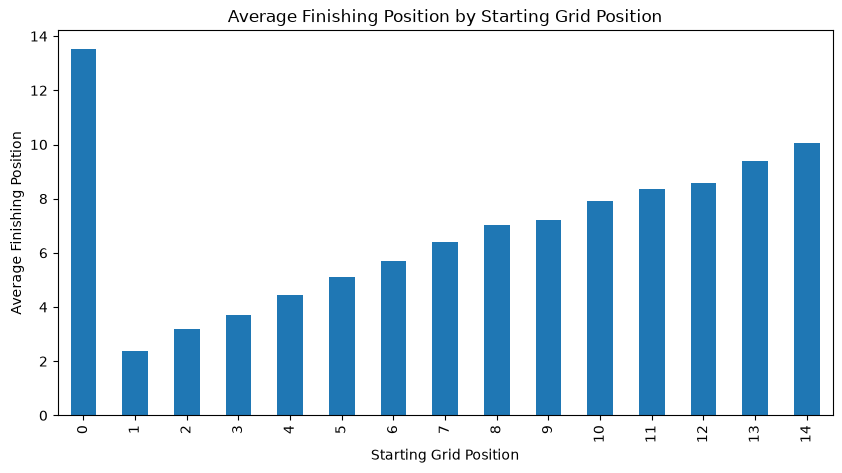

In [43]:
analysis = combined.dropna(subset=["grid", "position"])

analysis.groupby("grid")["position"].mean().head(15).plot(
    kind="bar",
    figsize=(10, 5),
    title="Average Finishing Position by Starting Grid Position",
    xlabel="Starting Grid Position",
    ylabel="Average Finishing Position"
)

In [1]:
import sys
!{sys.executable} -m pip install matplotlib

  Using cached matplotlib-3.11.1-cp313-cp313-win_amd64.whl.metadata (80 kB)
  Using cached contourpy-1.3.3-cp313-cp313-win_amd64.whl.metadata (5.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.63.0-cp313-cp313-win_amd64.whl.metadata (121 kB)
  Using cached kiwisolver-1.5.0-cp313-cp313-win_amd64.whl.metadata (5.2 kB)
  Using cached pyparsing-3.3.2-py3-none-any.whl.metadata (5.8 kB)
Using cached matplotlib-3.11.1-cp313-cp313-win_amd64.whl (9.3 MB)
Using cached contourpy-1.3.3-cp313-cp313-win_amd64.whl (226 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
Using cached fonttools-4.63.0-cp313-cp313-win_amd64.whl (2.3 MB)
Using cached kiwisolver-1.5.0-cp313-cp313-win_amd64.whl (73 kB)
Using cached pyparsing-3.3.2-py3-none-any.whl (122 kB)

   ---------------------------------------- 0/6 [pyparsing]
   ------------- -------------------------- 2/6 [fonttools]
   ------------- -------------------------- 2/6 [fonttools]
   ------------- --